In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

mamalaga_poverty_dataset_17_7k_path = kagglehub.dataset_download('mamalaga/poverty-dataset-17-7k')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
import os
for dirname, dirs, files in os.walk('/kaggle/input'):
    if any(f.endswith('.csv') for f in files):
        print(dirname)
        print(f"  Files: {len(files)}")

/kaggle/input/datasets/mamalaga/poverty-dataset-17-7k/dataset_34k
  Files: 17772


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
import pandas as pd
import numpy as np
from PIL import Image
import os
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [ ]:
DATASET_DIR = '/kaggle/input/datasets/mamalaga/poverty-dataset-17-7k/dataset_34k'
CSV_PATH    = '/kaggle/input/datasets/mamalaga/poverty-dataset-17-7k/dataset_34k/dataset.csv'
BATCH_SIZE  = 64
EPOCHS      = 30
LR          = 1e-4
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")

Using device: cuda


In [ ]:
def assign_class(score):
    if score < 0.33:
        return 0  # Wealthy
    elif score < 0.66:
        return 1  # Medium
    else:
        return 2  # Poor

CLASS_NAMES = ['Wealthy', 'Medium', 'Poor']

In [ ]:
class PovertyDataset(Dataset):
    def __init__(self, df, dataset_dir, transform=None):
        self.df          = df.reset_index(drop=True)
        self.dataset_dir = dataset_dir
        self.transform   = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row      = self.df.iloc[idx]
        img_path = os.path.join(self.dataset_dir, row['image'])
        image    = Image.open(img_path).convert('RGB')
        label    = assign_class(row['poverty_score'])
        if self.transform:
            image = self.transform(image)
        return image, label, row['center_lat'], row['center_lon'], row['poverty_score']

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

In [ ]:
df = pd.read_csv(CSV_PATH)
print(f"Total samples: {len(df)}")

df['class'] = df['poverty_score'].apply(assign_class)
print(f"Class distribution:\n{df['class'].value_counts()}")

train_df = df.sample(frac=0.70, random_state=42)
temp_df  = df.drop(train_df.index)
val_df   = temp_df.sample(frac=0.50, random_state=42)
test_df  = temp_df.drop(val_df.index)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

train_dataset = PovertyDataset(train_df, DATASET_DIR, train_transform)
val_dataset   = PovertyDataset(val_df,   DATASET_DIR, val_transform)
test_dataset  = PovertyDataset(test_df,  DATASET_DIR, val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

Total samples: 17771
Class distribution:
class
0    15701
1     1398
2      672
Name: count, dtype: int64
Train: 12440 | Val: 2666 | Test: 2665


In [ ]:
model = timm.create_model(
    'swin_tiny_patch4_window7_224',
    pretrained=True,
    num_classes=3
)

# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

# Unfreeze last stage + head
for name, param in model.named_parameters():
    if 'layers.3' in name or 'norm' in name or 'head' in name:
        param.requires_grad = True

model = model.to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {total_params:,} | Trainable: {trainable_params:,}")

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Total params: 27,521,661 | Trainable: 15,384,435


In [ ]:
class_counts  = df['class'].value_counts().sort_index()
total         = len(df)
class_weights = torch.tensor([
    total / (3 * class_counts[0]),
    total / (3 * class_counts[1]),
    total / (3 * class_counts[2])
], dtype=torch.float).to(DEVICE)

print(f"Class weights: {class_weights}")

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR,
    weight_decay=0.05
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

Class weights: tensor([0.3773, 4.2372, 8.8150], device='cuda:0')


In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct = 0, 0
    for batch in loader:
        images, labels = batch[0].to(DEVICE), batch[1].to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct    += (outputs.argmax(1) == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

def eval_epoch(model, loader, criterion):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for batch in loader:
            images, labels = batch[0].to(DEVICE), batch[1].to(DEVICE)
            outputs = model(images)
            loss    = criterion(outputs, labels)
            total_loss += loss.item()
            correct    += (outputs.argmax(1) == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

In [ ]:
train_losses, val_losses = [], []
train_accs,   val_accs   = [], []
best_val_acc = 0

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    val_loss,   val_acc   = eval_epoch(model, val_loader,   criterion)
    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/swin_tiny_best.pth')
        print(f" → Best model saved! Val Acc: {best_val_acc:.4f}")

Epoch 1/30 | Train Loss: 0.5567 Acc: 0.8527 | Val Loss: 0.4246 Acc: 0.8875
 → Best model saved! Val Acc: 0.8875
Epoch 2/30 | Train Loss: 0.4012 Acc: 0.8965 | Val Loss: 0.3787 Acc: 0.9239
 → Best model saved! Val Acc: 0.9239
Epoch 3/30 | Train Loss: 0.3383 Acc: 0.9093 | Val Loss: 0.3377 Acc: 0.9287
 → Best model saved! Val Acc: 0.9287
Epoch 4/30 | Train Loss: 0.2866 Acc: 0.9186 | Val Loss: 0.3206 Acc: 0.9351
 → Best model saved! Val Acc: 0.9351
Epoch 5/30 | Train Loss: 0.2528 Acc: 0.9293 | Val Loss: 0.3091 Acc: 0.9156
Epoch 6/30 | Train Loss: 0.2036 Acc: 0.9344 | Val Loss: 0.3291 Acc: 0.9377
 → Best model saved! Val Acc: 0.9377
Epoch 7/30 | Train Loss: 0.1783 Acc: 0.9438 | Val Loss: 0.3164 Acc: 0.9527
 → Best model saved! Val Acc: 0.9527
Epoch 8/30 | Train Loss: 0.1654 Acc: 0.9454 | Val Loss: 0.2976 Acc: 0.9325
Epoch 9/30 | Train Loss: 0.1374 Acc: 0.9518 | Val Loss: 0.2946 Acc: 0.9306
Epoch 10/30 | Train Loss: 0.1354 Acc: 0.9546 | Val Loss: 0.2715 Acc: 0.9437
Epoch 11/30 | Train Loss: 0

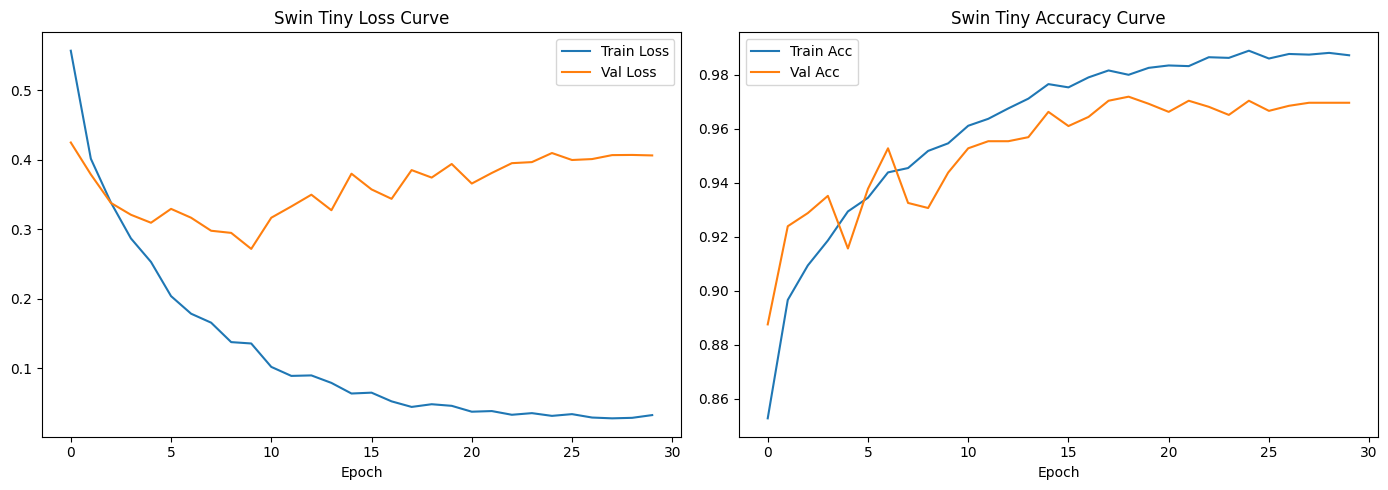

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses,   label='Val Loss')
ax1.set_title('Swin Tiny Loss Curve')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(train_accs, label='Train Acc')
ax2.plot(val_accs,   label='Val Acc')
ax2.set_title('Swin Tiny Accuracy Curve')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/swin_tiny_training_curves.png', dpi=150)
plt.show()

In [ ]:
model.load_state_dict(torch.load('/kaggle/working/swin_tiny_best.pth'))
model.eval()

all_preds, all_labels = [], []
all_lats,  all_lons   = [], []

with torch.no_grad():
    for batch in test_loader:
        images, labels, lats, lons, scores = batch
        images  = images.to(DEVICE)
        outputs = model(images)
        preds   = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        all_lats.extend(lats.numpy())
        all_lons.extend(lons.numpy())

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))


Classification Report:
              precision    recall  f1-score   support

     Wealthy       0.99      0.99      0.99      2338
      Medium       0.84      0.81      0.82       218
        Poor       0.90      0.94      0.92       109

    accuracy                           0.97      2665
   macro avg       0.91      0.91      0.91      2665
weighted avg       0.97      0.97      0.97      2665



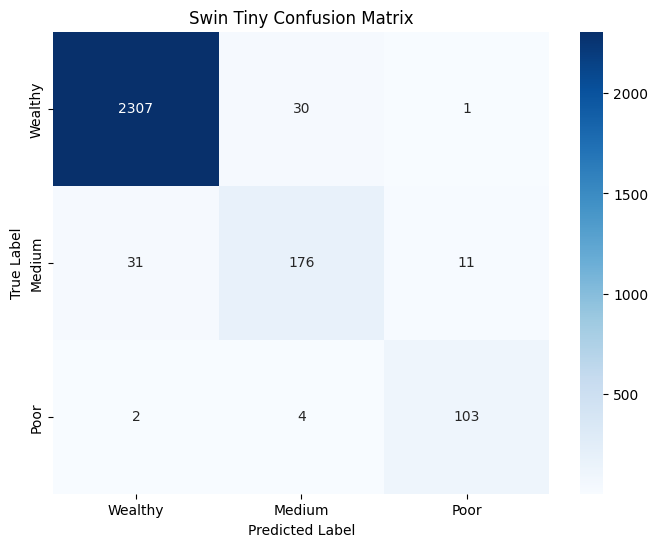

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES)
plt.title('Swin Tiny Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig('/kaggle/working/swin_tiny_confusion_matrix.png', dpi=150)
plt.show()

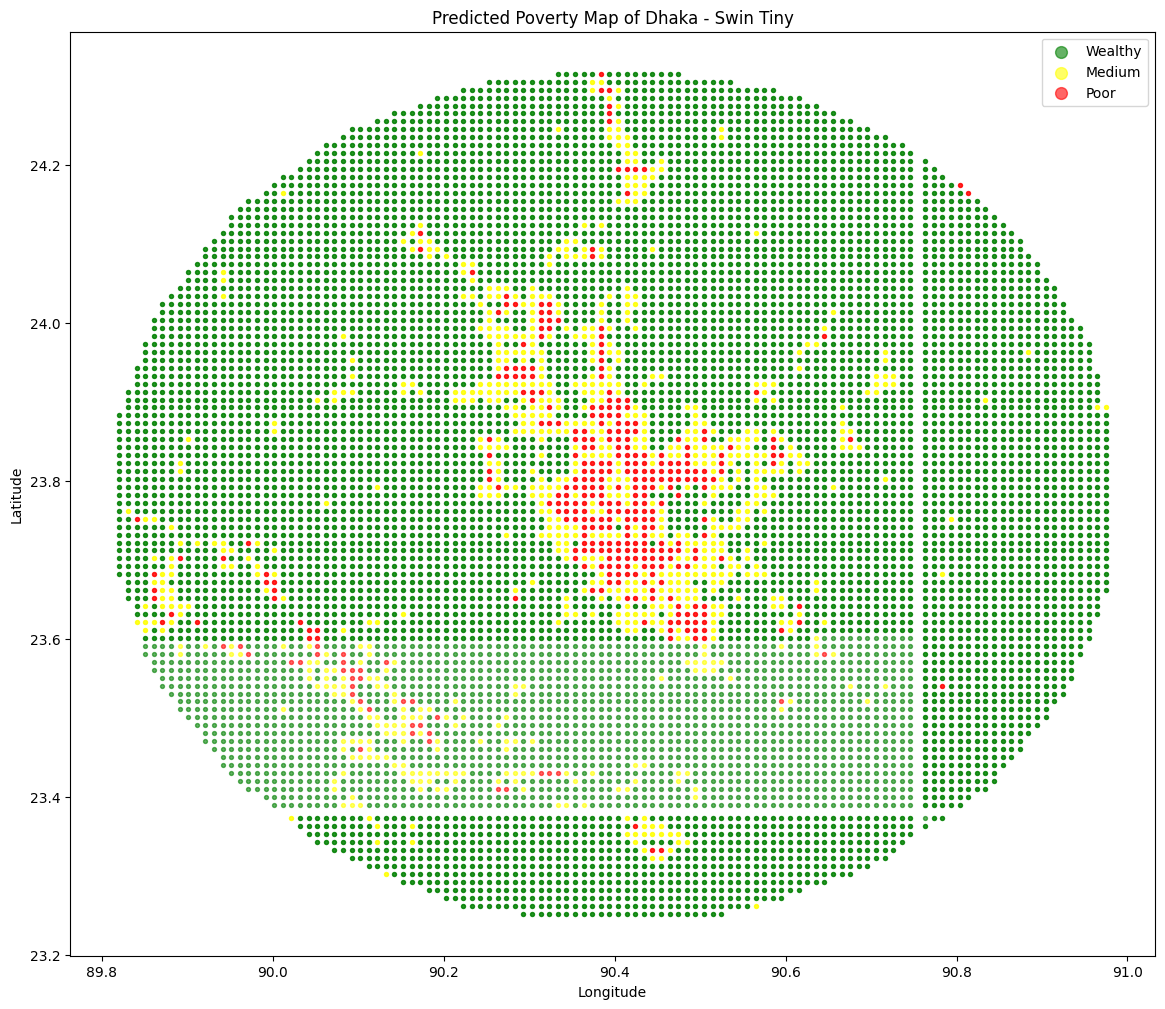

Poverty map saved!


In [ ]:
full_loader = DataLoader(
    PovertyDataset(df, DATASET_DIR, val_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

all_pred_classes, all_pred_lats, all_pred_lons = [], [], []

model.eval()
with torch.no_grad():
    for batch in full_loader:
        images, labels, lats, lons, scores = batch
        images  = images.to(DEVICE)
        outputs = model(images)
        preds   = outputs.argmax(1).cpu().numpy()
        all_pred_classes.extend(preds)
        all_pred_lats.extend(lats.numpy())
        all_pred_lons.extend(lons.numpy())

colors     = ['green', 'yellow', 'red']
labels_map = ['Wealthy', 'Medium', 'Poor']

plt.figure(figsize=(14, 12))
for cls in range(3):
    mask     = [p == cls for p in all_pred_classes]
    lons_cls = [all_pred_lons[i] for i in range(len(mask)) if mask[i]]
    lats_cls = [all_pred_lats[i] for i in range(len(mask)) if mask[i]]
    plt.scatter(lons_cls, lats_cls, c=colors[cls],
                label=labels_map[cls], s=8, alpha=0.6)

plt.title('Predicted Poverty Map of Dhaka - Swin Tiny')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(markerscale=3)
plt.savefig('/kaggle/working/swin_tiny_poverty_map.png', dpi=150)
plt.show()
print("Poverty map saved!")

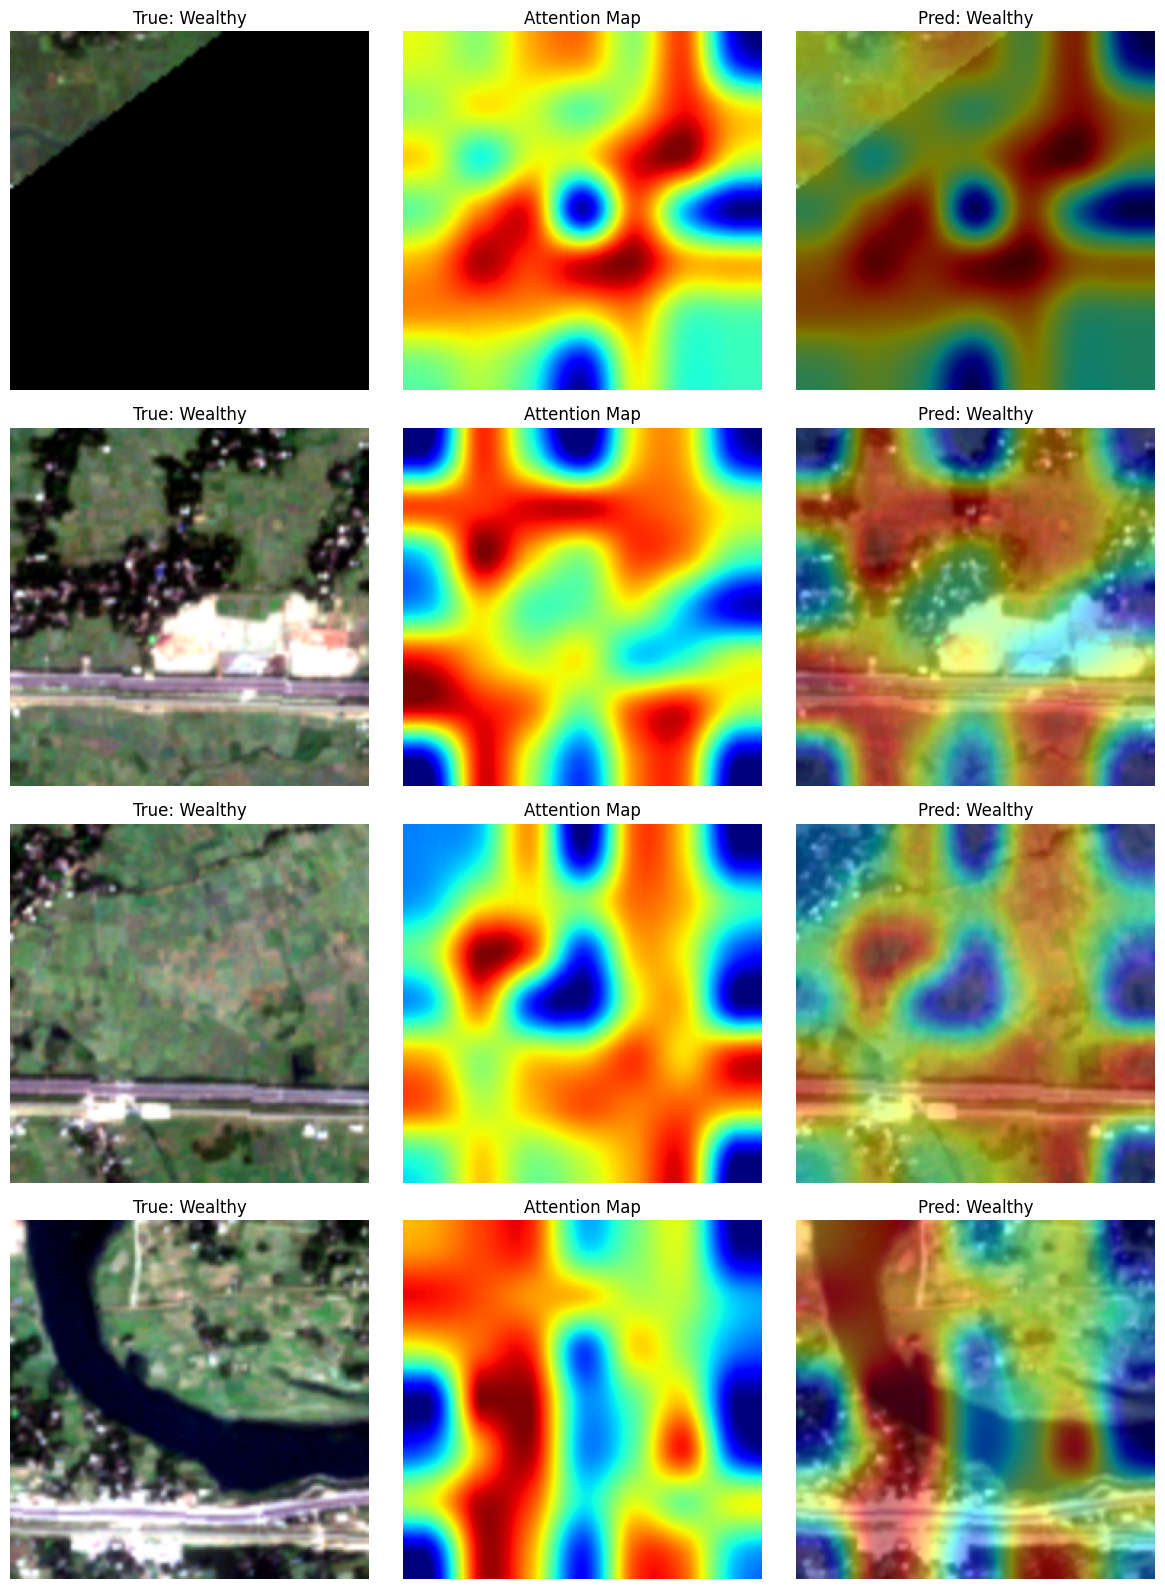

Attention maps saved!


In [ ]:
def get_swin_attention(model, image_tensor):
    model.eval()
    features = []

    def hook_fn(module, input, output):
        features.append(output)

    hook = model.layers[-1].register_forward_hook(hook_fn)

    with torch.no_grad():
        _ = model(image_tensor.unsqueeze(0).to(DEVICE))

    hook.remove()

    feat = features[0]

    # Handle all possible shapes coming out of Swin layers
    if len(feat.shape) == 4:  # (B, H, W, C)
        feat = feat.squeeze(0).mean(-1)        # → (H, W)
    elif len(feat.shape) == 3:  # (B, N, C) or (N, C) etc
        feat = feat.squeeze(0)
        if feat.shape[-1] > feat.shape[0]:     # (N, C) → mean over C
            feat = feat.mean(-1)
            n = feat.shape[0]
            grid_size = int(np.sqrt(n))
            feat = feat[:grid_size*grid_size].reshape(grid_size, grid_size)
        else:
            feat = feat.mean(-1)
    elif len(feat.shape) == 2:  # Already (H, W)
        pass  # use as-is

    feat = feat.cpu().numpy().astype(float)
    feat = (feat - feat.min()) / (feat.max() - feat.min() + 1e-8)
    return feat


fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for i in range(4):
    img_tensor, true_label, _, _, _ = test_dataset[i]
    pred_class = model(img_tensor.unsqueeze(0).to(DEVICE)).argmax(1).item()
    attn_map   = get_swin_attention(model, img_tensor)

    img_np = img_tensor.permute(1, 2, 0).numpy()
    img_np = img_np * 0.5 + 0.5
    img_np = np.clip(img_np, 0, 1)

    attn_resized = np.array(Image.fromarray((attn_map * 255).astype(np.uint8)).resize((224, 224)))

    axes[i][0].imshow(img_np)
    axes[i][0].set_title(f'True: {CLASS_NAMES[true_label]}')
    axes[i][0].axis('off')

    axes[i][1].imshow(attn_resized, cmap='jet')
    axes[i][1].set_title('Attention Map')
    axes[i][1].axis('off')

    axes[i][2].imshow(img_np)
    axes[i][2].imshow(attn_resized, cmap='jet', alpha=0.5)
    axes[i][2].set_title(f'Pred: {CLASS_NAMES[pred_class]}')
    axes[i][2].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/swin_tiny_attention_maps.png', dpi=150)
plt.show()
print("Attention maps saved!")